# Noise floor in the ROI: twin analysis (v2)

Same definition as v1 - noise = a nearly-identical set of predictors leading to different labels - with the space thinned by 4: `any_txn_last_24h` leaves the footprint and `txn_count_last_24h` joins the twin numerics as a real within-cell decile (9 numerics now), and `prior_disputes` is dropped entirely. Footprint: merchant tier x auth x device x is_new_merchant x any_cvv_retry = 480 theoretical cells.

Ladder (pre-registered): exact_9 (all 9 deciles), >=8, >=7, and profile (the four count_t signatures + product bucket, now over 9 numerics). Twin thresholds >=1/5/10, cells under 100 rows thin.

**Statistical note added in v2:** with k within-cell uniform deciles, the chance two random rows of the same cell match on all k is 10^-k - so the exact rung has essentially no power at any realistic cell size and its "zero" is a foregone conclusion, not evidence about noise. The informative rungs are >=7 and profile; a fuzzy (+/-1 per decile) rung is the honest way to pin the floor.

Also in this version: how `merchant_risk_score` behaves under `is_new_merchant = True` - distribution comparison (ROI and full train) and fraud rate per risk decile per group.


In [1]:
import importlib
import sys
from ccf_ml import file_utils
from ccf_ml.cross_validation import alarm as alarm_mod
importlib.reload(file_utils)
importlib.reload(alarm_mod)

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import (
    ALARM_FLAG_COLUMNS,
    ID_COLUMN,
    TARGET_COLUMN,
)
from ccf_ml.file_utils import (
    get_repo_root,
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
    get_training_oof_path,
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DELIMITER_VALUE = "-" * 50
NOTEBOOK_STEM = "noise_floor_roi"
EXP_NAME = "hgb_baseline"
PROB_COL = "y_prob"
FOLD_COL = "fold_id"
SCORE_CUT = 0.02
MERCHANT_COL = "merchant_category"
AUTH_COL = "auth_method"
DEVICE_COL = "device_type"
NEW_MERCHANT_COL = "is_new_merchant"
CVV_COL = "cvv_retry_count"
RISK_COL = "merchant_risk_score"
TXN24_COL = "txn_count_last_24h"
MERCHANT_TIERS = {
    "hot": ("Gift Cards", "Crypto Exchange", "Gaming"),
    "warm": ("Electronics", "Streaming"),
    "background": (
        "Travel",
        "Utilities",
        "Healthcare",
        "Fuel",
        "Restaurants",
        "Groceries",
        "Online Retail",
    ),
}
TIER_BY_MERCHANT = {
    merchant: tier
    for tier, merchants in MERCHANT_TIERS.items()
    for merchant in merchants
}
FP_COLUMNS = (
    "merchant_tier",
    AUTH_COL,
    DEVICE_COL,
    NEW_MERCHANT_COL,
    "any_cvv_retry",
)
TWIN_NUM = (
    "amount_usd",
    "hours_since_last_txn",
    "distance_from_home_km",
    "account_balance_usd",
    "velocity_score",
    "merchant_risk_score",
    "customer_age",
    "card_age_months",
    TXN24_COL,
)
COUNT_THRESHOLDS = (0.05, 0.10, 0.25, 0.50)
MIN_CELL = 100
FRAUD_CHUNK = 16
tables_dir = get_script_table_dir(NOTEBOOK_STEM)

train_df = pd.read_csv(get_train_csv_path())
oof_df = pd.read_csv(get_training_oof_path(EXP_NAME))
train_features = train_df.drop(columns=[TARGET_COLUMN])
frame = train_features.merge(oof_df, on=ID_COLUMN, how="inner", validate="one_to_one")
if len(frame) != len(train_df) or len(frame) != len(oof_df):
    raise ValueError(
        f"join lost rows: train={len(train_df)} oof={len(oof_df)} joined={len(frame)}"
    )
has_alarm = alarm_flag_mask(frame, columns=ALARM_FLAG_COLUMNS)
region = frame.loc[(~has_alarm) & (frame[PROB_COL] <= SCORE_CUT)].copy()
region["merchant_tier"] = region[MERCHANT_COL].map(TIER_BY_MERCHANT)
if region["merchant_tier"].isna().any():
    raise ValueError("unmapped merchant category inside the region")
region["any_cvv_retry"] = region[CVV_COL] > 0
n_region = len(region)
n_fraud_region = int((region[TARGET_COLUMN] == 1).sum())
rate_region = n_fraud_region / n_region
n_twin_num = len(TWIN_NUM)
EXACT_COL = f"exact_{n_twin_num}"
GE1_COL = f"ge{n_twin_num - 1}"
GE2_COL = f"ge{n_twin_num - 2}"
print("n_region", n_region)
print("n_fraud_region", n_fraud_region)
print("rate_region", round(rate_region, 6))
print("footprint columns", list(FP_COLUMNS))
print("twin numerics", list(TWIN_NUM))
print("ladder columns", EXACT_COL, GE1_COL, GE2_COL, "profile")
print("count thresholds", COUNT_THRESHOLDS)
print("min cell size for twin counting", MIN_CELL)


In [2]:
fp_groups = region.groupby(list(FP_COLUMNS), observed=True)
region["cell_id"] = fp_groups.ngroup()
cell_stats = fp_groups[TARGET_COLUMN].agg(n_cell="size", n_fraud_cell="sum")
cell_stats["rate_cell"] = cell_stats["n_fraud_cell"] / cell_stats["n_cell"]
theoretical_cells = 1
for _col in FP_COLUMNS:
    theoretical_cells *= int(region[_col].nunique())
print(f"theoretical cells {theoretical_cells}, observed {len(cell_stats)}, "
      f"usable (>= {MIN_CELL} rows) {int((cell_stats['n_cell'] >= MIN_CELL).sum())}")

pct_blocks = {}
for num in TWIN_NUM:
    pct = fp_groups[num].rank(pct=True)
    pct_blocks[num] = pct.to_numpy(dtype=np.float64)
    region[f"dec_{num}"] = np.minimum(
        (pct.to_numpy(dtype=np.float64) * 10.0).astype(np.int64), 9
    )
log_product = np.zeros(n_region, dtype=np.float64)
for num in TWIN_NUM:
    log_product += np.log10(region[f"dec_{num}"].to_numpy(dtype=np.float64) + 1.0)
region["log_product"] = log_product
region["prod_decile"] = np.minimum(
    (fp_groups["log_product"].rank(pct=True).to_numpy(dtype=np.float64) * 10.0).astype(np.int64),
    9,
)
for t in COUNT_THRESHOLDS:
    below = np.zeros(n_region, dtype=np.int64)
    for num in TWIN_NUM:
        below += (pct_blocks[num] <= t).astype(np.int64)
    region[f"count_leq_{t:.2f}"] = below

DEC_COLS = [f"dec_{num}" for num in TWIN_NUM]
PROF_COLS = [f"count_leq_{t:.2f}" for t in COUNT_THRESHOLDS] + ["prod_decile"]
dec_matrix = region[DEC_COLS].to_numpy(dtype=np.int64)
prof_matrix = region[PROF_COLS].to_numpy(dtype=np.int64)
y_arr = region[TARGET_COLUMN].to_numpy(dtype=np.int64)
cell_arr = region["cell_id"].to_numpy(dtype=np.int64)

fraud_pos = np.flatnonzero(y_arr == 1)
if len(fraud_pos) != n_fraud_region:
    raise ValueError("fraud count mismatch")
twin_rows: list[dict[str, object] | None] = [None] * n_fraud_region
n_thin = 0
row_i = 0
for cell_id in np.unique(cell_arr[fraud_pos]):
    in_cell = np.flatnonzero(cell_arr == cell_id)
    n_cell = len(in_cell)
    stats_row = cell_stats.iloc[cell_id]
    fraud_local = in_cell[y_arr[in_cell] == 1]
    if n_cell < MIN_CELL:
        n_thin += len(fraud_local)
        for pos in fraud_local:
            twin_rows[row_i] = {
                "pos": int(pos),
                "cell_id": int(cell_id),
                "n_cell": int(n_cell),
                "rate_cell": float(stats_row["rate_cell"]),
                "thin_cell": True,
                EXACT_COL: -1,
                GE1_COL: -1,
                GE2_COL: -1,
                "profile": -1,
            }
            row_i += 1
        continue
    nonfraud_local = in_cell[y_arr[in_cell] == 0]
    f_dec = dec_matrix[fraud_local]
    f_prof = prof_matrix[fraud_local]
    n_dec = dec_matrix[nonfraud_local]
    n_prof = prof_matrix[nonfraud_local]
    exact_counts = np.zeros(len(fraud_local), dtype=np.int64)
    ge1_counts = np.zeros(len(fraud_local), dtype=np.int64)
    ge2_counts = np.zeros(len(fraud_local), dtype=np.int64)
    prof_counts = np.zeros(len(fraud_local), dtype=np.int64)
    for start in range(0, len(fraud_local), FRAUD_CHUNK):
        stop = min(start + FRAUD_CHUNK, len(fraud_local))
        dec_match = (f_dec[start:stop, None, :] == n_dec[None, :, :]).sum(axis=2)
        prof_match = (f_prof[start:stop, None, :] == n_prof[None, :, :]).all(axis=2)
        exact_counts[start:stop] = (dec_match == n_twin_num).sum(axis=1)
        ge1_counts[start:stop] = (dec_match >= n_twin_num - 1).sum(axis=1)
        ge2_counts[start:stop] = (dec_match >= n_twin_num - 2).sum(axis=1)
        prof_counts[start:stop] = prof_match.sum(axis=1)
    for k in range(len(fraud_local)):
        twin_rows[row_i] = {
            "pos": int(fraud_local[k]),
            "cell_id": int(cell_id),
            "n_cell": int(n_cell),
            "rate_cell": float(stats_row["rate_cell"]),
            "thin_cell": False,
            EXACT_COL: int(exact_counts[k]),
            GE1_COL: int(ge1_counts[k]),
            GE2_COL: int(ge2_counts[k]),
            "profile": int(prof_counts[k]),
        }
        row_i += 1
if row_i != n_fraud_region:
    raise ValueError(f"twin row count mismatch: {row_i} vs {n_fraud_region}")
twin_table = pd.DataFrame([row for row in twin_rows if row is not None])
id_arr = region[ID_COLUMN].to_numpy()
prob_arr = region[PROB_COL].to_numpy(dtype=np.float64)
fold_arr = region[FOLD_COL].to_numpy()
pos_arr = twin_table["pos"].to_numpy(dtype=np.int64)
twin_table[ID_COLUMN] = id_arr[pos_arr]
twin_table[PROB_COL] = prob_arr[pos_arr]
twin_table[FOLD_COL] = fold_arr[pos_arr]
twin_table = twin_table.drop(columns=["pos"])
usable = twin_table.loc[~twin_table["thin_cell"]]
print(DELIMITER_VALUE)
print(f"frauds in thin cells (< {MIN_CELL} rows): {n_thin}")
print(f"frauds in usable cells: {len(usable)}")
print(DELIMITER_VALUE)
for level in (EXACT_COL, GE1_COL, GE2_COL, "profile"):
    series = usable[level]
    print(
        f"{level}: median {series.median():.0f}, "
        f">=1 twin: {(series >= 1).sum()}, "
        f">=5: {(series >= 5).sum()}, "
        f">=10: {(series >= 10).sum()}"
    )
twin_path = tables_dir / "noise2_fraud_twins.csv"
twin_table.to_csv(twin_path, index=False)
print("saved", twin_path)


theoretical cells 480, observed 448, usable (>= 100 rows) 241
--------------------------------------------------
frauds in thin cells (< 100 rows): 36
frauds in usable cells: 1638
--------------------------------------------------
exact_9: median 0, >=1 twin: 0, >=5: 0, >=10: 0
ge8: median 0, >=1 twin: 2, >=5: 0, >=10: 0
ge7: median 0, >=1 twin: 116, >=5: 0, >=10: 0
profile: median 18, >=1 twin: 1512, >=5: 1209, >=10: 997
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\noise_floor_roi\tables\noise2_fraud_twins.csv


twin ladder (v2, 480-cell space) over 1638 frauds in usable cells
match_level  frauds_with_0  frauds_ge_1  frauds_ge_5  frauds_ge_10  median_twins  mean_twins  share_ge_5
    exact_9           1638            0            0             0           0.0      0.0000      0.0000
        ge8           1636            2            0             0           0.0      0.0012      0.0000
        ge7           1522          116            0             0           0.0      0.0781      0.0000
    profile            126         1512         1209           997          18.0     68.0885      0.7381
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\noise_floor_roi\tables\noise2_twin_ladder.csv
--------------------------------------------------
v1 comparison (1920-cell space, 8 twin numerics, 1590 usable): exact_8 0/0/0, ge7 12/0/0, ge6 266/2/0, profile 1452/1099/903
                         group  n_frauds  share  mean_oof_prob  median_oof_prob  mean

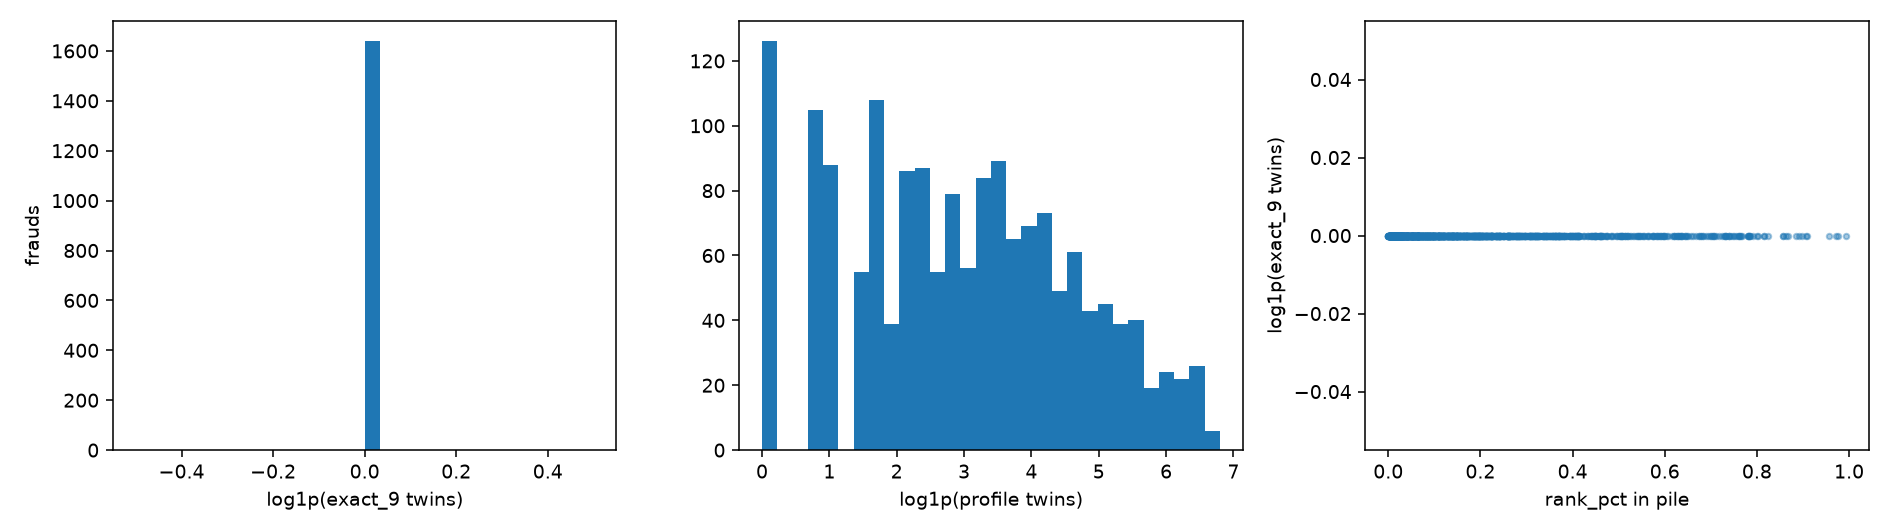

In [3]:
twin_table = pd.read_csv(tables_dir / "noise2_fraud_twins.csv")
ranks_path = get_script_table_dir("oof_alarm_region_auc") / "no_alarm_p_le_0p02_fraud_ranks.csv"
ranks = pd.read_csv(ranks_path)
twin_table = twin_table.merge(
    ranks[[ID_COLUMN, "rank", "rank_pct"]],
    on=ID_COLUMN,
    how="left",
    validate="one_to_one",
)
if twin_table["rank"].isna().any():
    raise ValueError("some frauds are missing ranks")
usable = twin_table.loc[~twin_table["thin_cell"]].copy()
n_usable = len(usable)

ladder_rows = []
for level in (EXACT_COL, GE1_COL, GE2_COL, "profile"):
    series = usable[level]
    ladder_rows.append(
        {
            "match_level": level,
            "frauds_with_0": int((series == 0).sum()),
            "frauds_ge_1": int((series >= 1).sum()),
            "frauds_ge_5": int((series >= 5).sum()),
            "frauds_ge_10": int((series >= 10).sum()),
            "median_twins": float(series.median()),
            "mean_twins": float(series.mean()),
            "share_ge_5": float((series >= 5).mean()),
        }
    )
ladder = pd.DataFrame(ladder_rows)
print("twin ladder (v2, 480-cell space) over", n_usable, "frauds in usable cells")
print(ladder.round(4).to_string(index=False))
ladder_path = tables_dir / "noise2_twin_ladder.csv"
ladder.to_csv(ladder_path, index=False)
print("saved", ladder_path)
print(DELIMITER_VALUE)
print("v1 comparison (1920-cell space, 8 twin numerics, 1590 usable): "
      "exact_8 0/0/0, ge7 12/0/0, ge6 266/2/0, profile 1452/1099/903")

noise_core = usable.loc[usable[EXACT_COL] >= 5].copy()
thin_zone = usable.loc[(usable["profile"] >= 5) & (usable[EXACT_COL] < 5)].copy()
distinct = usable.loc[(usable[EXACT_COL] < 5) & (usable["profile"] < 5)].copy()
groups = (
    (f"noise_core (>=5 {EXACT_COL} twins)", noise_core),
    ("thin_zone (>=5 profile)", thin_zone),
    ("distinct (<5 on both)", distinct),
)
group_rows = []
for name, part in groups:
    if len(part) == 0:
        group_rows.append({"group": name, "n_frauds": 0})
        continue
    group_rows.append(
        {
            "group": name,
            "n_frauds": len(part),
            "share": len(part) / n_usable,
            "mean_oof_prob": float(part[PROB_COL].mean()),
            "median_oof_prob": float(part[PROB_COL].median()),
            "mean_cell_rate": float(part["rate_cell"].mean()),
            "median_rank_pct": float(part["rank_pct"].median()),
        }
    )
group_table = pd.DataFrame(group_rows)
print(group_table.round(4).to_string(index=False))
group_path = tables_dir / "noise2_groups.csv"
group_table.to_csv(group_path, index=False)
print("saved", group_path)
print(DELIMITER_VALUE)
if len(distinct):
    print("distinct group: the missed-pattern hunting ground (worst-ranked first)")
    print(
        distinct.sort_values("rank_pct", ascending=False)
        .head(10)[
            [ID_COLUMN, FOLD_COL, PROB_COL, "rank_pct", "n_cell", "rate_cell", EXACT_COL, GE1_COL, "profile"]
        ]
        .to_string(index=False)
    )
    distinct_path = tables_dir / "noise2_distinct_frauds.csv"
    distinct.to_csv(distinct_path, index=False)
    print("saved", distinct_path)

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="twins")
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
axes[0].hist(np.log1p(usable[EXACT_COL].to_numpy(dtype=np.float64)), bins=30)
axes[0].set_xlabel(f"log1p({EXACT_COL} twins)")
axes[0].set_ylabel("frauds")
axes[1].hist(np.log1p(usable["profile"].to_numpy(dtype=np.float64)), bins=30)
axes[1].set_xlabel("log1p(profile twins)")
axes[2].scatter(
    usable["rank_pct"].to_numpy(dtype=np.float64),
    np.log1p(usable[EXACT_COL].to_numpy(dtype=np.float64)),
    s=8,
    alpha=0.4,
)
axes[2].set_xlabel("rank_pct in pile")
axes[2].set_ylabel(f"log1p({EXACT_COL} twins)")
fig.tight_layout()
twins_plot = plot_dir / "noise2_twins.png"
fig.savefig(twins_plot, dpi=140)
print("saved", twins_plot)


[roi] merchant_risk_score by is_new_merchant
                    count     mean      std  min   10%   25%   50%   75%   90%    max
is_new_merchant                                                                      
False            514623.0  34.2793  12.0104  0.0  19.6  25.9  33.3  41.6  49.9  100.0
True              75447.0  32.3995  11.1491  0.0  18.7  24.7  31.6  39.3  47.1  100.0
KS D=0.0690 p=1.2e-272; mean(new - old)=-1.8798 (z=-42.8)
--------------------------------------------------
[all_train] merchant_risk_score by is_new_merchant
                    count     mean      std  min   10%   25%   50%   75%   90%    max
is_new_merchant                                                                      
False            593240.0  35.1700  12.6078  0.0  19.9  26.4  34.1  42.7  51.5  100.0
True             106720.0  35.4825  12.7388  0.0  20.1  26.6  34.4  43.0  51.9  100.0
KS D=0.0127 p=4.49e-13; mean(new - old)=+0.3125 (z=+7.4)
--------------------------------------------------

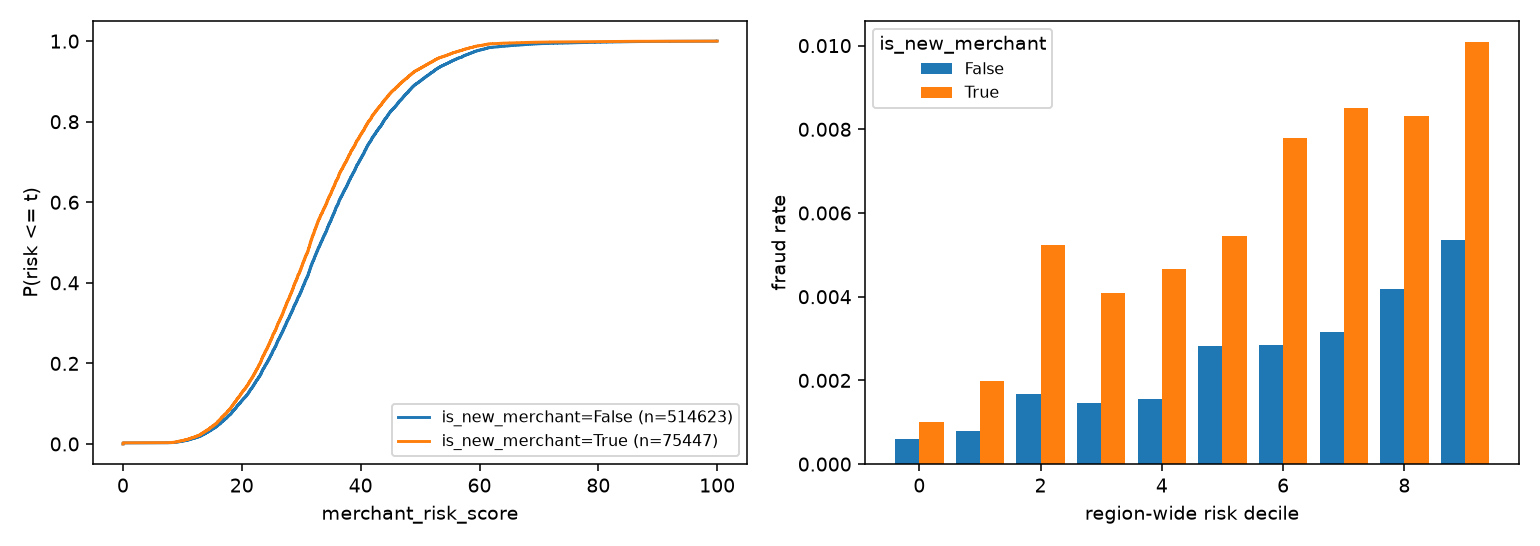

In [4]:
from scipy.stats import ks_2samp

for scope_name, source in (("roi", region), ("all_train", frame)):
    new = source.loc[source[NEW_MERCHANT_COL], RISK_COL].to_numpy(dtype=np.float64)
    old = source.loc[~source[NEW_MERCHANT_COL], RISK_COL].to_numpy(dtype=np.float64)
    ks_stat, ks_p = ks_2samp(new, old)
    mean_diff = float(new.mean() - old.mean())
    se_diff = float(np.sqrt(new.var() / len(new) + old.var() / len(old)))
    print(f"[{scope_name}] merchant_risk_score by {NEW_MERCHANT_COL}")
    print(
        source.groupby(NEW_MERCHANT_COL)[RISK_COL]
        .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
        .round(4)
        .to_string()
    )
    print(
        f"KS D={ks_stat:.4f} p={ks_p:.3g}; "
        f"mean(new - old)={mean_diff:+.4f} (z={mean_diff / se_diff:+.1f})"
    )
    print(DELIMITER_VALUE)

region["risk_dec"] = pd.qcut(region[RISK_COL], 10, labels=False, duplicates="drop")
rate_pivot = (
    region.groupby(["risk_dec", NEW_MERCHANT_COL], observed=True)[TARGET_COLUMN]
    .agg(n="size", n_fraud="sum")
    .reset_index()
)
rate_pivot["rate"] = rate_pivot["n_fraud"] / rate_pivot["n"]
pivot_wide = rate_pivot.pivot(index="risk_dec", columns=NEW_MERCHANT_COL, values="rate")
print("fraud rate by region-wide risk decile x is_new_merchant (ROI)")
print(pivot_wide.round(5).to_string())
rate_path = tables_dir / "risk_decile_by_new_merchant.csv"
rate_pivot.to_csv(rate_path, index=False)
print("saved", rate_path)
print(DELIMITER_VALUE)
fraud_by_new = region.groupby(NEW_MERCHANT_COL, observed=True)[TARGET_COLUMN].agg(
    n="size", n_fraud="sum"
)
fraud_by_new["rate"] = fraud_by_new["n_fraud"] / fraud_by_new["n"]
print("ROI fraud rate by is_new_merchant for reference")
print(fraud_by_new.round(5).to_string())

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="new_merchant_risk")
fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.9))
for flag, part in region.groupby(NEW_MERCHANT_COL, observed=True):
    scores = np.sort(part[RISK_COL].to_numpy(dtype=np.float64))
    cdf = np.arange(1, len(scores) + 1) / len(scores)
    label = f"{NEW_MERCHANT_COL}={flag} (n={len(scores)})"
    axes[0].plot(scores, cdf, label=label)
axes[0].set_xlabel(RISK_COL)
axes[0].set_ylabel("P(risk <= t)")
axes[0].legend(fontsize=8)
deciles = np.arange(pivot_wide.shape[0])
width = 0.4
axes[1].bar(deciles - width / 2, pivot_wide[False].to_numpy(dtype=np.float64), width, label="False")
axes[1].bar(deciles + width / 2, pivot_wide[True].to_numpy(dtype=np.float64), width, label="True")
axes[1].set_xlabel("region-wide risk decile")
axes[1].set_ylabel("fraud rate")
axes[1].legend(title=NEW_MERCHANT_COL, fontsize=8)
fig.tight_layout()
risk_plot = plot_dir / "new_merchant_risk.png"
fig.savefig(risk_plot, dpi=140)
print("saved", risk_plot)


## Takeaway: v2

1. **Space:** 1,920 -> 480 theoretical cells (448 observed, 241 usable at >= 100 rows). Measurable frauds 1,590 -> 1,638; thin-cell frauds 84 -> 36.

2. **exact_9 is still zero - and now correctly interpreted.** Not one fraud has a single 9/9-decile non-fraud twin, even inside cells of 40k rows. With 9 within-cell uniform deciles the expected random exact match is n_cell x 10^-9, so this rung could never fire; its zero says nothing about noise. The same applies to v1's exact_8.

3. **The informative rungs.** >=7/9 near-twins: 116 frauds have at least one (v1, 6/8: 266). Profile twins: 74% of frauds have >=5 (1,209 of 1,638; v1: 69%). Coarsening the categorical space moved the mid-rungs only slightly - the numeric fingerprint, not the cell size, is the binding constraint.

4. **The distinct group persists:** 429 frauds unique even at profile level, mean OOF probability 0.0094 vs mean cell rate 0.0086 - ranked at local background inside cells running 3-11x the region rate. Worst cases: id 540148 (cell 1.50%, score 7e-6), 29768, 326219 (inside a 40,708-row cell). `noise2_distinct_frauds.csv`.

5. **Next rung to actually pin the floor:** fuzzy matching (every decile within +/-1), or exact match on numeric subsets - the mid-resolution region where the decision actually lives.

6. **is_new_merchant x merchant_risk_score.** Inside the ROI, new merchants sit slightly *lower* on risk (mean 32.4 vs 34.3, KS D = 0.069) yet carry roughly *double* the fraud rate at every single risk decile (decile 2: 0.52% vs 0.17%; decile 9: 1.01% vs 0.54%). The two signals are close to multiplicative - new-merchant is a x2 premium on top of risk, not a slope change - and risk alone would naively call new merchants slightly safer. On the full train the two risk distributions are identical (mean difference 0.3), so the ROI shift is selection into the low-score pile, not a generator link.
